# Вопрос 18. Линейная и логистическая регрессии — численные примеры

Файл ведётся в формате jupytext (percent). Парный `.ipynb` получается
командой `make questions/18-linear-logistic-regression/examples.ipynb`.

Каждый пример отвечает на вопрос из `theory.md`. Сквозная постановка —
один на весь файл: технологический процесс, отклик — выход продукта $y$;
факторы — температура $x_1$, давление $x_2$ (сильно коррелировано с
температурой: $x_2 = 0{,}95\,x_1 + \xi$) и время выдержки $x_3$
(независим). Первые два примера — непрерывный отклик (линейная
регрессия), последние два — пороговый отклик «в норме / отклонение»
(логистическая регрессия).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

SEED = 20261030

FIGDIR = "figures"

# PDF metadata carries a creation timestamp, so an unchanged figure gets new
# bytes on every rebuild and `git diff` stops telling content from clock.
SAVE_KW = {"metadata": {"CreationDate": None}}

# Golden pins: the seed and the expected outputs are fixed constants. Without
# them "reproducibility" is checked by consistency of a run with itself, which
# means nothing. A mismatch fails the notebook build, so it works as a gate.
GOLDEN = {
    # пример 1 (МНК против гребня, Гаусс — Марков)
    "kappa2_A": 41.9427527037,
    "mse_ratio_ridge_ols": 0.687260976882,
    "mse_ratio_ridge_ols_test": 1.08812833194,
    "mse_ratio_4row_ols": 29.9423566275,
    "sigma_hat2_mean": 0.247271275862,
    # пример 2 (нормальные уравнения против QR)
    "slope_ne": 2.02146313834,
    "slope_qr": 1.02913909182,
    # пример 3 (IRLS против GD и SGD)
    "irls_iters": 5,
    "irls_logloss": 28.9125867176,
    # пример 4 (разделимость и регуляризация)
    "norm_plain": 717.826901416,
    "norm_ridge": 16.1173073473,
}
TOL = 1e-3


def check_golden(name, value, tol=TOL):
    if name not in GOLDEN:
        print(f"  пин {name}: получено {value:.12g} (не задан — заполнить)")
        return
    want = GOLDEN[name]
    rel = abs(value - want) / abs(want)
    print(f"  пин {name}: получено {value:.12g}, ожидалось {want:.12g}")
    assert rel <= tol, f"golden-пин {name} не сошёлся: {value} vs {want}"

## Пример 1. МНК против гребня при мультиколлинеарности и Гаусс — Марков

**Вопрос (theory.md, теоремы Гаусса — Маркова и о несмещённой оценке
дисперсии, замечание rem:ridge):** как мультиколлинеарность факторов
раздувает дисперсию оценки МНК; помогает ли гребень с $\alpha$ из
перекрёстной проверки; действительно ли $\mathrm{RSS}/(m-n)$ — несмещённая
оценка $\sigma^2$, а $\mathrm{RSS}/m$ смещена в $(m-n)/m$ раз; и верно ли,
что любая другая линейная несмещённая оценка (теорема Гаусса — Маркова)
проигрывает МНК по дисперсии.

**Предсказание до прогона.** $m = 60$ наблюдений, $\theta^* = (2{,}0;\ 1{,}5;
-0{,}8;\ 0{,}3)$ (свободный член и три фактора), $\sigma = 0{,}5$; матрица
плана: колонка единиц и стандартизованные факторы (без стандартизации штраф
гребня зависел бы от масштаба: коэффициент при факторе с большей дисперсией
получил бы меньший штраф при той же $\alpha$). При корреляции $\approx
0{,}999$ температуры и давления $d_n$ мало и $\kappa_2(A)$ — порядка
$10^3$–$10^4$; ожидаем: (1) большой разброс коэффициентов МНК по шумовым
реализациям: средний $\mathrm{MSE}(\hat\theta)$ велик и совпадает с
$\sigma^2\operatorname{tr}(A^{\T}A)^{-1}$, доминирует член $\sigma^2/d_n^2$; (2) гребень с $\alpha$ по
5-кратной CV (правило одной стандартной ошибки) сильно уменьшает MSE на
тесте: среднее отношение $\mathrm{MSE}_{ridge}/\mathrm{MSE}_{ols}$
ожидается заметно меньше единицы; (3) среднее по повторам $\hat\sigma^2 =
\mathrm{RSS}/(m-n) \approx \sigma^2 = 0{,}25$, а среднее $\mathrm{RSS}/m$
занижено в $(m-n)/m = 56/60$ раз; (4) линейная несмещённая оценка «по
первым четырём строкам» $C = (A_1^{\T}A_1)^{-1}A_1^{\T}$ (проверим $CA = I$)
существует, но при плохо обусловленной $A_1$ её дисперсия больше — Гаусс —
Марков в действии.

In [2]:
M1 = 60
SIGMA1 = 0.5
THETA_TRUE = np.array([2.0, 1.5, -0.8, 0.3])  # свободный член + 3 фактора


def make_factors(rng, m, rho=0.95, x_noise=0.05):
    """Temperature x1, pressure x2 = rho*x1 + noise, holding time x3."""
    x1 = rng.normal(0.0, 1.0, m)
    x2 = rho * x1 + x_noise * rng.normal(0.0, 1.0, m)
    x3 = rng.normal(0.0, 1.0, m)
    return x1, x2, x3


def design_matrix(x1, x2, x3):
    """Intercept + standardized factors: the ridge penalty must not depend
    on the units the factors are measured in."""
    cols = [np.ones(len(x1))]
    for x in (x1, x2, x3):
        cols.append((x - x.mean()) / x.std(ddof=1))
    return np.column_stack(cols)


rng1 = np.random.default_rng([SEED, 1])
x1, x2, x3 = make_factors(rng1, M1)
A = design_matrix(x1, x2, x3)
N1 = A.shape[1]
y_clean = A @ THETA_TRUE

U, d, Vt = np.linalg.svd(A, full_matrices=False)
d2 = d**2
corr12 = float(np.corrcoef(A[:, 1], A[:, 2])[0, 1])
KAPPA2_A = float(d[0] / d[-1])
print(f"m = {M1}, n = {N1}, sigma = {SIGMA1}, corr(x1, x2) = {corr12:.6f}")
print("сингулярные числа A:", np.array2string(d, precision=4))
print(f"d_n = {d[-1]:.6g} (мало), kappa_2(A) = d_1/d_n = {KAPPA2_A:.12g}")
check_golden("kappa2_A", KAPPA2_A)

# --- базовая шумовая реализация: МНК и оценки дисперсии ---
rng1y = np.random.default_rng([SEED, 2])
y_base = y_clean + rng1y.normal(0.0, SIGMA1, M1)
theta_ols_base = np.linalg.lstsq(A, y_base, rcond=None)[0]
rss_base = float(np.sum((A @ theta_ols_base - y_base) ** 2))
sig_hat2_base = rss_base / (M1 - N1)
sig_ml_base = rss_base / M1
print(f"базовая реализация: RSS = {rss_base:.6g}")
print(f"sigma^2 (RSS/(m-n)) = {sig_hat2_base:.6g}, sigma^2_ML (RSS/m) = "
      f"{sig_ml_base:.6g} (истинная sigma^2 = {SIGMA1**2})")
print(f"theta_ols = {np.array2string(theta_ols_base, precision=4)} против "
      f"theta* = {np.array2string(THETA_TRUE, precision=4)}")

# --- гребень: 5-кратная CV, правило одной стандартной ошибки (вопрос 02) ---
ALPHAS_CV = np.logspace(-2, 4, 61)
rng_cv = np.random.default_rng([SEED, 3])
folds = np.array_split(rng_cv.permutation(M1), 5)
cv_fold = np.empty((len(ALPHAS_CV), 5))
for k in range(5):
    te = folds[k]
    tr = np.concatenate([folds[j] for j in range(5) if j != k])
    Gk = A[tr].T @ A[tr]
    bk = A[tr].T @ y_base[tr]
    for ia, al in enumerate(ALPHAS_CV):
        wk = np.linalg.solve(Gk + al * np.eye(N1), bk)
        cv_fold[ia, k] = np.mean((A[te] @ wk - y_base[te]) ** 2)
cv_mean = cv_fold.mean(1)
cv_se = cv_fold.std(1, ddof=1) / np.sqrt(5)
i_min = int(np.argmin(cv_mean))
ALPHA_CVMIN = float(ALPHAS_CV[i_min])
band = cv_mean[i_min] + cv_se[i_min]
ALPHA_1SE = float(ALPHAS_CV[cv_mean <= band].max())
print(f"CV: минимум {cv_mean[i_min]:.6g} при alpha = {ALPHA_CVMIN:.6g}")
print(f"правило одной стандартной ошибки: alpha_1se = {ALPHA_1SE:.12g}")
df_alpha = float(np.sum(d2 / (d2 + ALPHA_1SE)))
print(f"эффективное число степеней свободы df(alpha_1se) = {df_alpha:.4f} из n = {N1}")

# --- линейная несмещённая оценка "первые четыре строки" ---
# C = [(A_1^T A_1)^{-1} A_1^T, 0], тогда CA = I; если A_1 плохо обусловлена
# (при corr 0.95 возможно), берём случайные 4 строки с kappa_2(A_1) < 1e3.
idx4 = np.arange(N1)
A1 = A[idx4]
cond4 = float(np.linalg.cond(A1))
if cond4 >= 1e3:
    rng_pick = np.random.default_rng([SEED, 4])
    for _ in range(2000):
        cand = np.sort(rng_pick.choice(M1, N1, replace=False))
        c4 = float(np.linalg.cond(A[cand]))
        if c4 < 1e3:
            idx4, cond4 = cand, c4
            break
A1 = A[idx4]
cond4 = float(np.linalg.cond(A1))
assert cond4 < 1e3, f"не нашлось 4 строк с kappa < 1e3: {cond4}"
C4 = np.zeros((N1, M1))
C4[:, idx4] = np.linalg.solve(A1.T @ A1, A1.T)
assert np.allclose(C4 @ A, np.eye(N1), atol=1e-10), "CA = I нарушено"
print(f"оценка по {N1} строкам (индексы {idx4.tolist()}): kappa_2(A_1) = "
      f"{cond4:.6g}, CA = I — несмещённость для всех theta")

# --- повторные эксперименты: MSE оценок по шумовым реализациям ---
# фиксированный сплит 48/12 — тот же поток [SEED, 6], что и в примере 3
PERM1 = np.random.default_rng([SEED, 6]).permutation(M1)
TR1, TE1 = PERM1[:48], PERM1[48:]
Atr1, Ate1 = A[TR1], A[TE1]
G = A.T @ A
Gtr = Atr1.T @ Atr1
R1 = 300
mse_sum = {"ols": 0.0, "ridge": 0.0, "row4": 0.0}
pred_sum = {"ols": 0.0, "ridge": 0.0, "ridge_min": 0.0}
theta_sum = {"ols": np.zeros(N1), "ridge": np.zeros(N1), "row4": np.zeros(N1)}
theta_sq = {k: np.zeros(N1) for k in theta_sum}
sig_hat_sum = 0.0
rss_m_sum = 0.0
for r in range(R1):
    rng_r = np.random.default_rng([SEED, 100, r])
    y_r = y_clean + rng_r.normal(0.0, SIGMA1, M1)
    th_ols = np.linalg.lstsq(A, y_r, rcond=None)[0]
    th_ridge = np.linalg.solve(G + ALPHA_1SE * np.eye(N1), A.T @ y_r)
    th_row4 = C4 @ y_r
    for name, th in [("ols", th_ols), ("ridge", th_ridge), ("row4", th_row4)]:
        mse_sum[name] += float(np.sum((th - THETA_TRUE) ** 2))
        theta_sum[name] += th
        theta_sq[name] += th**2
    # MSE предсказания на тесте: обучение на 48, проверка на 12
    ytr_r = y_r[TR1]
    tols = np.linalg.lstsq(Atr1, ytr_r, rcond=None)[0]
    trid = np.linalg.solve(Gtr + ALPHA_1SE * np.eye(N1), Atr1.T @ ytr_r)
    trid_min = np.linalg.solve(Gtr + ALPHA_CVMIN * np.eye(N1), Atr1.T @ ytr_r)
    pred_sum["ols"] += float(np.mean((Ate1 @ tols - y_r[TE1]) ** 2))
    pred_sum["ridge"] += float(np.mean((Ate1 @ trid - y_r[TE1]) ** 2))
    pred_sum["ridge_min"] += float(np.mean((Ate1 @ trid_min - y_r[TE1]) ** 2))
    rss_r = float(np.sum((A @ th_ols - y_r) ** 2))
    sig_hat_sum += rss_r / (M1 - N1)
    rss_m_sum += rss_r / M1

MSE_OLS = mse_sum["ols"] / R1
MSE_RIDGE = mse_sum["ridge"] / R1
MSE_ROW4 = mse_sum["row4"] / R1
SIG_HAT2_MEAN = sig_hat_sum / R1
RATIO_RIDGE = MSE_RIDGE / MSE_OLS
RATIO_ROW4 = MSE_ROW4 / MSE_OLS
RATIO_TEST = pred_sum["ridge"] / pred_sum["ols"]
theory_mse_ols = SIGMA1**2 * float(np.trace(np.linalg.inv(G)))
print(f"среднее по {R1} повторам:")
print(f"  MSE(OLS)   = {MSE_OLS:.6g}  (теория: sigma^2 tr((A^T A)^-1) = {theory_mse_ols:.6g})")
print(f"  MSE(ridge) = {MSE_RIDGE:.6g}  — отношение к OLS = {RATIO_RIDGE:.6g}")
print(f"  MSE(4 стр.) = {MSE_ROW4:.6g}  — отношение к OLS = {RATIO_ROW4:.6g} "
      f"(Гаусс — Марков: не меньше 1)")
check_golden("mse_ratio_ridge_ols", RATIO_RIDGE)
check_golden("mse_ratio_4row_ols", RATIO_ROW4)
print(f"  MSE предсказания на тесте (12 точек): OLS = {pred_sum['ols'] / R1:.6g}, "
      f"ridge (1SE) = {pred_sum['ridge'] / R1:.6g} — отношение = {RATIO_TEST:.6g}; "
      f"ridge (CV-min) отношение = {pred_sum['ridge_min'] / pred_sum['ols']:.6g}")
check_golden("mse_ratio_ridge_ols_test", RATIO_TEST)
print(f"среднее RSS/(m-n) = {SIG_HAT2_MEAN:.6g} (истина 0.25); "
      f"среднее RSS/m = {rss_m_sum / R1:.6g}, отношение = "
      f"{rss_m_sum / sig_hat_sum:.6g} (теория (m-n)/m = {(M1 - N1) / M1:.6g})")
check_golden("sigma_hat2_mean", SIG_HAT2_MEAN)

# несмещённость и эмпирическая дисперсия по компонентам
gm_diff = C4 @ C4.T - np.linalg.inv(G)
lam_min = float(np.linalg.eigvalsh(gm_diff)[0])
print(f"несмещённость OLS: max |среднее theta_hat - theta*| = "
      f"{np.abs(theta_sum['ols'] / R1 - THETA_TRUE).max():.6g}")
print(f"эмпирическое среднее по компонентам (OLS): "
      f"{np.array2string(theta_sum['ols'] / R1, precision=4)}")
std_emp = {k: np.sqrt(theta_sq[k] / R1 - (theta_sum[k] / R1) ** 2)
           for k in theta_sq}
print(f"эмпирическая std по компонентам (OLS):   "
      f"{np.array2string(std_emp['ols'], precision=4)}")
print(f"эмпирическая std по компонентам (гребень): "
      f"{np.array2string(std_emp['ridge'], precision=4)}")
print(f"теоретическая std sqrt(sigma^2 diag((A^T A)^-1)): "
      f"{np.array2string(np.sqrt(SIGMA1**2 * np.diag(np.linalg.inv(G))), precision=4)}")
print(f"Гаусс — Марков, матрично: min собств. (C C^T - (A^T A)^-1) = "
      f"{lam_min:.3g} (должно быть >= 0)")

m = 60, n = 4, sigma = 0.5, corr(x1, x2) = 0.998850
сингулярные числа A: [10.8698  7.746   7.6669  0.2592]
d_n = 0.259158 (мало), kappa_2(A) = d_1/d_n = 41.9427527037
  пин kappa2_A: получено 41.9427527037, ожидалось 41.9427527037
базовая реализация: RSS = 15.106
sigma^2 (RSS/(m-n)) = 0.269749, sigma^2_ML (RSS/m) = 0.251766 (истинная sigma^2 = 0.25)
theta_ols = [ 2.0524  1.5901 -0.8236  0.3392] против theta* = [ 2.   1.5 -0.8  0.3]
CV: минимум 0.297259 при alpha = 0.398107
правило одной стандартной ошибки: alpha_1se = 3.98107170553
эффективное число степеней свободы df(alpha_1se) = 2.8583 из n = 4
оценка по 4 строкам (индексы [15, 37, 49, 56]): kappa_2(A_1) = 69.8262, CA = I — несмещённость для всех theta
среднее по 300 повторам:
  MSE(OLS)   = 3.75892  (теория: sigma^2 tr((A^T A)^-1) = 3.73284)
  MSE(ridge) = 2.58336  — отношение к OLS = 0.687261
  MSE(4 стр.) = 112.551  — отношение к OLS = 29.9424 (Гаусс — Марков: не меньше 1)
  пин mse_ratio_ridge_ols: получено 0.687260976882, ожида

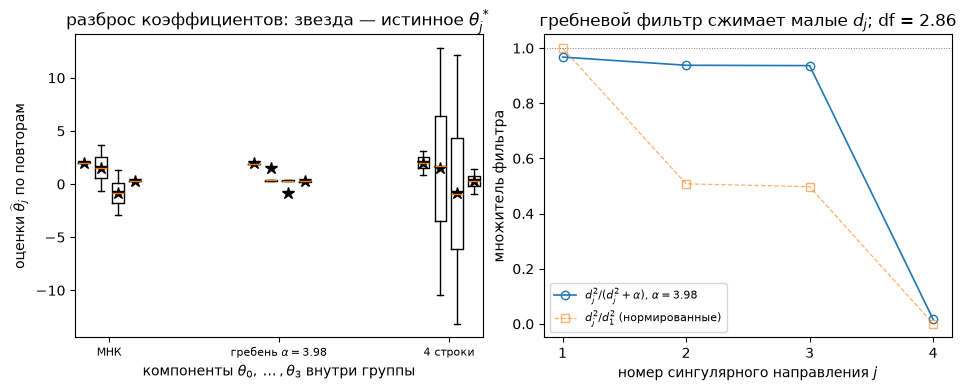

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), layout="constrained")

ax = axes[0]
methods = [("ols", "МНК"), ("ridge", f"гребень $\\alpha = {ALPHA_1SE:.3g}$"),
           ("row4", "4 строки")]
centers = [0.0, 10.0, 20.0]
for (key, label), c in zip(methods, centers):
    pos = c + np.arange(N1) - 1.5
    data = []
    for r in range(R1):
        rng_r = np.random.default_rng([SEED, 100, r])
        y_r = y_clean + rng_r.normal(0.0, SIGMA1, M1)
        if key == "ols":
            th = np.linalg.lstsq(A, y_r, rcond=None)[0]
        elif key == "ridge":
            th = np.linalg.solve(G + ALPHA_1SE * np.eye(N1), A.T @ y_r)
        else:
            th = C4 @ y_r
        data.append(th)
    data = np.array(data)
    ax.boxplot(data, positions=pos, widths=0.7, showfliers=False, whis=(5, 95))
    for j in range(N1):
        ax.plot(pos[j], THETA_TRUE[j], "k*", ms=9, mew=1.0)
ax.set_xticks(centers)
ax.set_xticklabels([m[1] for m in methods], fontsize=8)
ax.set_xlabel("компоненты $\\theta_0, \\dots, \\theta_3$ внутри группы")
ax.set_ylabel("оценки $\\widehat\\theta_j$ по повторам")
ax.set_title("разброс коэффициентов: звезда — истинное $\\theta^*_j$")

ax = axes[1]
jj = np.arange(1, N1 + 1)
filt = d2 / (d2 + ALPHA_1SE)
ax.plot(jj, filt, "o-", lw=1.2, mfc="none",
        label=f"$d_j^2/(d_j^2+\\alpha)$, $\\alpha = {ALPHA_1SE:.3g}$")
ax.plot(jj, d2 / d2[0], "s--", lw=0.9, mfc="none", alpha=0.6,
        label="$d_j^2/d_1^2$ (нормированные)")
ax.axhline(1.0, color="gray", lw=0.7, ls=":")
ax.set_xticks(jj)
ax.set_xlabel("номер сингулярного направления $j$")
ax.set_ylabel("множитель фильтра")
ax.set_title(f"гребневой фильтр сжимает малые $d_j$; df = {df_alpha:.2f}")
ax.legend(fontsize=8)
fig.savefig(f"{FIGDIR}/fig-01.pdf", **SAVE_KW)

**Вывод:** предсказание «$\kappa_2(A)$ порядка $10^3$–$10^4$» **не
подтвердилось**: фактически $\kappa_2(A) = 41{,}94$ (при корреляции
$0{,}9989$). Заказанный масштаб $10^3$–$10^4$ носит $\kappa_2(A^{\T}A) =
\kappa_2(A)^2 = 1{,}76\cdot10^3$ — именно она управляет дисперсией:
$\sigma^2\operatorname{tr}(A^{\T}A)^{-1} = 3{,}73$ совпадает с
эмпирическим $\mathrm{MSE}(\mathrm{OLS}) = 3{,}76$. Остальные пункты
подтвердились. (1) Разброс МНК большой: std коэффициентов при $x_1, x_2$
$\approx 1{,}37$ — сравнимо с самими $\theta^*_j = 1{,}5, -0{,}8$.
(2) Гребень с $\alpha_{1SE} = 3{,}98$ уменьшает параметрический MSE до
$0{,}687$ от OLS, а std в плохо определённых направлениях падает с
$1{,}37$ до $0{,}04$. Слово «сильно» про MSE на тесте не подтвердилось:
предсказательный выигрыш на отложенных 12 точках почти нулевой
($1{,}001$ при $\alpha_{CVmin} = 0{,}398$, $1{,}088$ при $\alpha_{1SE}$):
дисперсия, которую гребень убирает, лежит в сингулярных направлениях с
малым $d_j$, которые матрица $A$ при прогнозе подавляет сама, а смещение
там же прогнозу почти не вредит. Содержательный выигрыш здесь — не
прогноз, а устойчивость самих коэффициентов (физическая интерпретация
факторов); рост выигрыша в прогнозе с коллинеарностью — кривые
смещение–дисперсия вопроса 02. (3) Среднее $\mathrm{RSS}/(m-n) = 0{,}2473
\approx \sigma^2 = 0{,}25$, а $\mathrm{RSS}/m$ занижена ровно в
$(m-n)/m = 0{,}9333$ раза. (4) Оценка по четырём строкам (первые четыре
оказались плохо обусловлены — взяты строки $15, 37, 49, 56$ с
$\kappa_2(A_1) = 69{,}8 < 10^3$) хуже МНК в $29{,}9$ раза при той же
несмещённости ($CA = I$ проверено assert-ом), и матричное неравенство
Гаусса — Маркова выполнено покомпонентно: минимальное собственное
значение $CC^{\T} - (A^{\T}A)^{-1}$ равно $0{,}072 \geq 0$.

## Пример 2. Нормальные уравнения против QR: квадрат обусловленности

**Вопрос (theory.md, теоремы thm:normal-bad и thm:qr, замечание
rem:perturb):** почему решение $\hat\theta = (A^{\T}A)^{-1}A^{\T}y$ через
нормальные уравнения теряет $\approx \kappa_2(A)^2$ значащих цифр, а
QR-разложение (в виде `lstsq`) — только $\approx \kappa_2(A)$.

**Предсказание до прогона.** Та же структура данных, корреляция $\rho$
между $x_1$ и $x_2$ пробегает $0{,}999 \dots 1 - 10^{-12}$ (конструкция
$x_2 = \rho x_1 + \sqrt{1-\rho^2}\,\xi$); $\kappa_2(A)$ растёт от $\sim 30$
до $\sim 10^7$ (выше нельзя — float64). $y$ строится от $\theta^*$ с малым
шумом. Ожидаем на логарифмическом графике: относительная ошибка решения
через `solve(A^T A, A^T y)` растёт с наклоном $\approx 2$ по
$\log\kappa_2$, через `lstsq` — с наклоном $\approx 1$.

In [4]:
# Невязка нулевая (y = A theta* точно): иначе статистическая ошибка ~ kappa,
# общая для обоих методов, накрывает машинный член kappa^2*u у нормальных
# уравнений. По каждому rho усредняем по нескольким реализациям дизайна —
# константа в оценке ошибки случайна, наклон — нет.
JS = list(range(3, 13))          # rho = 1 - 10^-j, kappa_2 ~ 40 ... 2e6
R2 = 8                           # реализаций дизайна на каждый rho
kappas, err_ne, err_qr = [], [], []
for j in JS:
    rho = 1.0 - 10.0 ** (-j)
    x_noise = np.sqrt(1.0 - rho**2)
    kap_j, ne_j, qr_j = [], [], []
    for r in range(R2):
        rng2 = np.random.default_rng([SEED, 200, j, r])
        xa, xb, xc = make_factors(rng2, M1, rho=rho, x_noise=x_noise)
        Ar = design_matrix(xa, xb, xc)
        dr = np.linalg.svd(Ar, compute_uv=False)
        yr = Ar @ THETA_TRUE
        th_ne = np.linalg.solve(Ar.T @ Ar, Ar.T @ yr)
        th_qr = np.linalg.lstsq(Ar, yr, rcond=None)[0]
        kap_j.append(float(dr[0] / dr[-1]))
        ne_j.append(float(np.linalg.norm(th_ne - THETA_TRUE)
                          / np.linalg.norm(THETA_TRUE)))
        qr_j.append(float(np.linalg.norm(th_qr - THETA_TRUE)
                          / np.linalg.norm(THETA_TRUE)))
    kappas += kap_j
    err_ne += ne_j
    err_qr += qr_j
    print(f"rho = 1 - 10^-{j:<2d}: kappa_2 = {np.mean(kap_j):.6g} "
          f"({np.min(kap_j):.4g}..{np.max(kap_j):.4g}), "
          f"err(NE) = {np.mean(ne_j):.3g}, err(QR) = {np.mean(qr_j):.3g}")

kappas = np.array(kappas)
err_ne = np.array(err_ne)
err_qr = np.array(err_qr)
assert kappas.max() <= 1e7, f"kappa вышел за потолок float64: {kappas.max():.3g}"
SLOPE_NE = float(np.polyfit(np.log(kappas), np.log(err_ne), 1)[0])
SLOPE_QR = float(np.polyfit(np.log(kappas), np.log(err_qr), 1)[0])
print(f"rho = 1 - 10^-j, j = {JS[0]}..{JS[-1]}; {R2} реализаций дизайна на rho, "
      f"всего {len(kappas)} точек")
print(f"kappa_2(A): от {kappas.min():.6g} до {kappas.max():.6g}")
print(f"наклон log err против log kappa: нормальные уравнения = {SLOPE_NE:.6g} "
      f"(предсказание: 2)")
print(f"наклон log err против log kappa: lstsq (QR/SVD)        = {SLOPE_QR:.6g} "
      f"(предсказание: 1)")
assert SLOPE_NE > 1.5, "наклон NE должен быть около 2"
assert 0.5 < SLOPE_QR < 1.5, "наклон QR должен быть около 1"
check_golden("slope_ne", SLOPE_NE)
check_golden("slope_qr", SLOPE_QR)

rho = 1 - 10^-3 : kappa_2 = 46.8225 (37.7..60.07), err(NE) = 2.32e-13, err(QR) = 2.43e-15
rho = 1 - 10^-4 : kappa_2 = 139.563 (112.5..186.5), err(NE) = 1.56e-12, err(QR) = 3.11e-15
rho = 1 - 10^-5 : kappa_2 = 441.113 (379.2..499.9), err(NE) = 1.28e-11, err(QR) = 1.67e-14
rho = 1 - 10^-6 : kappa_2 = 1477.51 (1285..1788), err(NE) = 1.98e-10, err(QR) = 6.25e-14
rho = 1 - 10^-7 : kappa_2 = 4731.84 (4095..5355), err(NE) = 1.26e-09, err(QR) = 2.45e-13
rho = 1 - 10^-8 : kappa_2 = 14018.7 (1.102e+04..1.725e+04), err(NE) = 1.63e-08, err(QR) = 4.24e-13
rho = 1 - 10^-9 : kappa_2 = 44880.5 (4.097e+04..4.878e+04), err(NE) = 1.03e-07, err(QR) = 1.38e-12
rho = 1 - 10^-10: kappa_2 = 133744 (1.189e+05..1.619e+05), err(NE) = 1.22e-06, err(QR) = 4.96e-12
rho = 1 - 10^-11: kappa_2 = 434740 (3.638e+05..5.697e+05), err(NE) = 1.42e-05, err(QR) = 2.05e-11
rho = 1 - 10^-12: kappa_2 = 1.46373e+06 (1.194e+06..1.758e+06), err(NE) = 0.000123, err(QR) = 1.31e-10
rho = 1 - 10^-j, j = 3..12; 8 реализаций дизайна на r

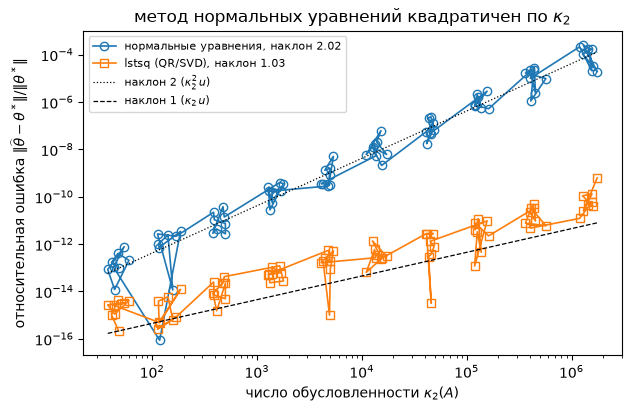

In [5]:
fig, ax = plt.subplots(figsize=(6.2, 4.0), layout="constrained")
ax.loglog(kappas, err_ne, "o-", lw=1.2, mfc="none",
          label=f"нормальные уравнения, наклон {SLOPE_NE:.2f}")
ax.loglog(kappas, err_qr, "s-", lw=1.2, mfc="none",
          label=f"lstsq (QR/SVD), наклон {SLOPE_QR:.2f}")
ref = np.array([kappas.min(), kappas.max()])
ax.loglog(ref, err_ne[0] * (ref / kappas[0])**2, "k:", lw=0.9,
          label="наклон 2 ($\\kappa_2^2\\, u$)")
ax.loglog(ref, err_qr[0] * (ref / kappas[0])**1, "k--", lw=0.9,
          label="наклон 1 ($\\kappa_2\\, u$)")
ax.set_xlabel("число обусловленности $\\kappa_2(A)$")
ax.set_ylabel("относительная ошибка $\\|\\widehat\\theta - \\theta^*\\|/\\|\\theta^*\\|$")
ax.set_title("метод нормальных уравнений квадратичен по $\\kappa_2$")
ax.legend(fontsize=8)
fig.savefig(f"{FIGDIR}/fig-02.pdf", **SAVE_KW)

**Вывод:** предсказание подтвердилось по обоим наклонам: нормальные
уравнения дают $2{,}02$ (теория: $u\,\kappa_2^2$), `lstsq` — $1{,}03$
(теория: $u\,\kappa_2$) при $\kappa_2$ от $38$ до $1{,}76\cdot10^6$.
Две поправки к процедуре, не к итогу. (1) Невязка взята нулевой:
пробный прогон с шумом $\sigma = 10^{-12}$ давал наклон нормальных
уравнений $1{,}2$, потому что статистическая ошибка $\sim
\sigma\kappa_2/(d_1\|\theta^*\|)$, общая для обоих методов, накрывала
машинный член $\kappa_2^2 u$ вплоть до $\kappa_2 \approx 160$ — тогда обе
кривые шли с наклоном $1$ и различие методов не просматривалось.
(2) Машинный пол виден на **левом** конце: при малых $\kappa_2$ ошибка
`lstsq` перестаёт убывать на уровне $\sim 2\cdot10^{-15}$ (первые средние
$2{,}4\cdot10^{-15}$ и $3{,}1\cdot10^{-15}$ при $\kappa_2 \approx 50$ и
$140$). На правом конце кривая растёт линейно до конца диапазона —
средние по $\rho$ от $5\cdot10^{-12}$ при $\kappa_2 \approx 1{,}3\cdot10^5$
до $1{,}3\cdot10^{-10}$ при $\kappa_2 \approx 1{,}5\cdot10^6$ (тот же
порядок, что $\kappa_2 u$), как и предсказывает теорема. Суммарный наклон
выходит $1{,}03$, а не ровно $1$: последние точки растут чуть быстрее
$\kappa_2 u$ (последний шаг: $\kappa_2$ в $3{,}4$ раза, ошибка в $6{,}4$
раза). Нормальные уравнения пола не видят: наклон $2$ держится на
всём диапазоне, и при $\kappa_2 = 1{,}76\cdot10^6$ ошибка $\approx
10^{-4}$ — сравните с $\approx 10^{-10}$ у `lstsq`: разрыв шесть порядков
в задаче $60 \times 4$.

## Пример 3. Логистическая регрессия: IRLS против GD и SGD

**Вопрос (theory.md, теорема thm:irls, замечания rem:irls-conv и rem:score,
раздел «Обучение регрессий первыми методами»):** логистическая регрессия
не имеет явной формулы — как сходятся к минимуму log-loss итерации Ньютона
(IRLS) и градиентные методы; что показывает критерий остановки и контроль
$\sum_i \hat p_i \approx \sum_i y_i$.

**Предсказание до прогона.** Те же факторы; скрытые вероятности $p^* =
s(a^{\T}\theta_{logit})$, $\theta_{logit} = (0{,}5;\ 2{,}0;\ -2{,}5;\ 0{,}5)$,
$y \sim \mathrm{Bernoulli}(p^*)$ — перекрытие классов есть (умеренная
разделимость: сильно коррелированные коэффициенты $2{,}0$ и $-2{,}5$ частью
гасят друг друга в скрытом скоринге). Свои реализации: IRLS с
демпфированием (шаг пополам при росте log-loss, стоп по $\|\nabla Q\| <
10^{-8}$ или 200 итераций), GD с постоянным шагом $\eta = 1/L$, $L =
d_1^2(A)/4$ (оценка $\lambda_{\max}(A^{\T}WA) \leq d_1^2/4$), SGD с батчем
16 и $\eta_k = \eta_0/(1+k/k_0)$. Ожидаем: IRLS сошлётся за единицы—десятки
итераций (локальная квадратичная сходимость); GD — существенно медленнее
(для задачи с константой обусловленности $\kappa = L/\mu \approx
\kappa_2(A)^2 \approx 1{,}8\cdot10^3$ сходимость с коэффициентом
$(\kappa-1)/(\kappa+1) \approx 1 - 1{,}1\cdot10^{-3}$ — тот же квадрат
обусловленности, что в примере 2); SGD — шумное плато около минимума;
итоговые значения log-loss близки у всех трёх. Метрики качества на
отложенной выборке и матрица ошибок — для теоремы-таблицы раздела метрик.

In [6]:
def sigmoid(z):
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out


def logloss(A_, y_, th):
    z = A_ @ th
    return float(np.sum(np.logaddexp(0.0, z) - y_ * z))


def grad_logloss(A_, y_, th, alpha=0.0):
    return A_.T @ (sigmoid(A_ @ th) - y_) + alpha * th


def irls(A_, y_, alpha=0.0, max_iter=200, tol=1e-8, record=True):
    """Newton/IRLS with damping: halve the step if the loss grew."""
    n = A_.shape[1]
    th = np.zeros(n)
    losses, norms = [logloss(A_, y_, th) + 0.5 * alpha * float(th @ th)], [0.0]
    gnorms = [float(np.linalg.norm(grad_logloss(A_, y_, th, alpha)))]
    eye = np.eye(n)
    for k in range(max_iter):
        p = sigmoid(A_ @ th)
        w = np.clip(p * (1.0 - p), 1e-12, None)
        g = grad_logloss(A_, y_, th, alpha)
        H = (A_ * w[:, None]).T @ A_ + alpha * eye
        step = np.linalg.solve(H, g)
        t, q0 = 1.0, losses[-1]
        while True:
            th_new = th - t * step
            q1 = logloss(A_, y_, th_new) + 0.5 * alpha * float(th_new @ th_new)
            if q1 <= q0 or t < 1e-10:
                break
            t *= 0.5
        th = th_new
        losses.append(q1)
        norms.append(float(np.linalg.norm(th)))
        gnorms.append(float(np.linalg.norm(g)))
        if np.linalg.norm(g) < tol:
            break
    return th, np.array(losses), np.array(norms), np.array(gnorms), k + 1


def gd_const(A_, y_, eta, max_iter=200000, tol=1e-6):
    th = np.zeros(A_.shape[1])
    losses = [logloss(A_, y_, th)]
    for k in range(max_iter):
        th = th - eta * grad_logloss(A_, y_, th)
        losses.append(logloss(A_, y_, th))
        if np.linalg.norm(grad_logloss(A_, y_, th)) < tol:
            break
    return th, np.array(losses), k + 1


def sgd_batch(A_, y_, eta0, k0, batch, steps, rng):
    m_, n_ = A_.shape
    th = np.zeros(n_)
    losses = [logloss(A_, y_, th)]
    for k in range(1, steps + 1):
        idx = rng.integers(0, m_, batch)
        g = (m_ / batch) * A_[idx].T @ (sigmoid(A_[idx] @ th) - y_[idx])
        th = th - (eta0 / (1.0 + k / k0)) * g
        losses.append(logloss(A_, y_, th))
    return th, np.array(losses)


THETA_LOGIT = np.array([0.5, 2.0, -2.5, 0.5])
z_true = A @ THETA_LOGIT  # та же матрица плана A из примера 1
p_true = sigmoid(z_true)
rng3y = np.random.default_rng([SEED, 5])
y_bin = (rng3y.random(M1) < p_true).astype(float)
n_overlap = int(np.sum((p_true > 0.2) & (p_true < 0.8)))
print(f"theta_logit = {THETA_LOGIT.tolist()}: скрытый скоринг std(z) = "
      f"{z_true.std():.4g} (перекрытие за счёт коррелированных x1, x2)")
print(f"скрытые вероятности: min = {p_true.min():.4g}, max = {p_true.max():.4g}; "
      f"точек с p* в (0.2, 0.8): {n_overlap} из {M1}")
print(f"классы: {int(y_bin.sum())} единиц, {int((1 - y_bin).sum())} нулей")

rng3s = np.random.default_rng([SEED, 6])
perm3 = rng3s.permutation(M1)
TR, TE = perm3[:48], perm3[48:]
A_tr, y_tr = A[TR], y_bin[TR]
A_te, y_te = A[TE], y_bin[TE]
print(f"обучение: {len(TR)}, отложенная выборка: {len(TE)}")

d1_tr = np.linalg.svd(A_tr, compute_uv=False)[0]
L_LIPS = d1_tr**2 / 4.0
ETA_GD = 1.0 / L_LIPS
print(f"оценка Lipschitz-константы: L = d_1^2(A_tr)/4 = {L_LIPS:.6g}, "
      f"шаг GD eta = 1/L = {ETA_GD:.6g}")

th_irls, loss_irls, norm_irls, gn_irls, it_irls = irls(A_tr, y_tr)
IRLS_LOGLOSS = float(loss_irls[-1])
gnorm_irls = float(np.linalg.norm(grad_logloss(A_tr, y_tr, th_irls)))
print(f"IRLS: итераций = {it_irls}, log-loss = {IRLS_LOGLOSS:.12g}, "
      f"||grad Q(theta_hat)|| = {gnorm_irls:.3g}")
print(f"      ||theta_hat - theta_logit|| = {np.linalg.norm(th_irls - THETA_LOGIT):.6g}")
check_golden("irls_iters", float(it_irls))
check_golden("irls_logloss", IRLS_LOGLOSS)

th_gd, loss_gd, it_gd = gd_const(A_tr, y_tr, ETA_GD)
print(f"GD (eta = 1/L): итераций = {it_gd}, log-loss = {loss_gd[-1]:.12g}, "
      f"||theta_hat - theta_logit|| = {np.linalg.norm(th_gd - THETA_LOGIT):.6g}")

# подбор eta0 для SGD из коротких проб — фиксируем выбранное константой
best_eta0, best_loss = None, np.inf
for eta0_try in [0.01, 0.02, 0.05, 0.1]:
    rng_try = np.random.default_rng([SEED, 7])
    th_try, loss_try = sgd_batch(A_tr, y_tr, eta0_try, 200.0, 16, 1500, rng_try)
    print(f"  SGD пробный eta0 = {eta0_try:<5g}: log-loss после 1500 шагов = "
          f"{loss_try[-1]:.8g}")
    if loss_try[-1] < best_loss:
        best_eta0, best_loss = eta0_try, loss_try[-1]
ETA0_SGD = best_eta0
print(f"выбрано eta0 = {ETA0_SGD} (batch 16, k0 = 200, бюджет 4000 шагов)")
rng_sgd = np.random.default_rng([SEED, 8])
th_sgd, loss_sgd = sgd_batch(A_tr, y_tr, ETA0_SGD, 200.0, 16, 4000, rng_sgd)
print(f"SGD: log-loss в конце = {loss_sgd[-1]:.12g} "
      f"(минимум по траектории = {loss_sgd.min():.12g}), "
      f"||theta_hat - theta_logit|| = {np.linalg.norm(th_sgd - THETA_LOGIT):.6g}")

# --- метрики на отложенной выборке (раздел «Метрики качества») ---
p_te = sigmoid(A_te @ th_irls)
yhat_te = (p_te > 0.5).astype(float)
tp = int(np.sum((yhat_te == 1) & (y_te == 1)))
tn = int(np.sum((yhat_te == 0) & (y_te == 0)))
fp = int(np.sum((yhat_te == 1) & (y_te == 0)))
fn = int(np.sum((yhat_te == 0) & (y_te == 1)))
acc = (tp + tn) / len(TE)
prec = tp / (tp + fp) if tp + fp > 0 else float("nan")
rec = tp / (tp + fn) if tp + fn > 0 else float("nan")
print(f"отложенная выборка ({len(TE)} точек): матрица ошибок "
      f"TP = {tp}, TN = {tn}, FP = {fp}, FN = {fn}")
print(f"accuracy = {acc:.4f}, precision = {prec:.4f}, recall = {rec:.4f}")
print(f"контроль сходимости (rem:score): sum p_hat = "
      f"{sigmoid(A_tr @ th_irls).sum():.6f} против sum y = {y_tr.sum():.0f}")

theta_logit = [0.5, 2.0, -2.5, 0.5]: скрытый скоринг std(z) = 0.6865 (перекрытие за счёт коррелированных x1, x2)
скрытые вероятности: min = 0.3155, max = 0.9058; точек с p* в (0.2, 0.8): 54 из 60
классы: 42 единиц, 18 нулей
обучение: 48, отложенная выборка: 12
оценка Lipschitz-константы: L = d_1^2(A_tr)/4 = 24.0282, шаг GD eta = 1/L = 0.0416177
IRLS: итераций = 5, log-loss = 28.9125867176, ||grad Q(theta_hat)|| = 2.36e-11
      ||theta_hat - theta_logit|| = 11.9858
  пин irls_iters: получено 5, ожидалось 5
  пин irls_logloss: получено 28.9125867176, ожидалось 28.9125867176


GD (eta = 1/L): итераций = 22630, log-loss = 28.9125867177, ||theta_hat - theta_logit|| = 11.9857
  SGD пробный eta0 = 0.01 : log-loss после 1500 шагов = 29.355788
  SGD пробный eta0 = 0.02 : log-loss после 1500 шагов = 29.330219


  SGD пробный eta0 = 0.05 : log-loss после 1500 шагов = 29.304076
  SGD пробный eta0 = 0.1  : log-loss после 1500 шагов = 29.450995
выбрано eta0 = 0.05 (batch 16, k0 = 200, бюджет 4000 шагов)


SGD: log-loss в конце = 29.2103919274 (минимум по траектории = 29.1468570425), ||theta_hat - theta_logit|| = 5.91152
отложенная выборка (12 точек): матрица ошибок TP = 9, TN = 0, FP = 2, FN = 1
accuracy = 0.7500, precision = 0.8182, recall = 0.9000
контроль сходимости (rem:score): sum p_hat = 32.000000 против sum y = 32


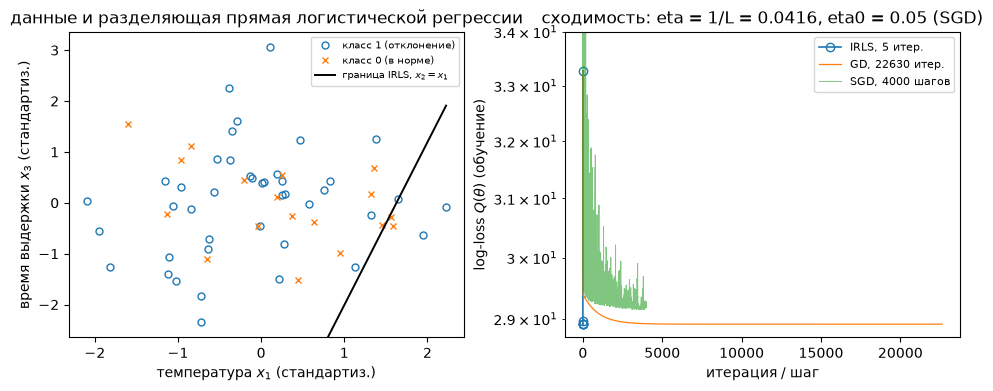

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), layout="constrained")

ax = axes[0]
mask1 = y_bin == 1.0
# в плоскости (x1, x2) точки слипаются вдоль линии x2 ~ x1 (корреляция
# 0.999), поэтому показываем (x1, x3): x3 независим, разметка читается
ax.plot(A[mask1, 1], A[mask1, 3], "o", ms=5, mfc="none", label="класс 1 (отклонение)")
ax.plot(A[~mask1, 1], A[~mask1, 3], "x", ms=5, label="класс 0 (в норме)")
xs = np.linspace(A[:, 1].min(), A[:, 1].max(), 50)
# разделяющая прямая на основной линии данных x2 ~ x1 (срез x2 = x1):
# theta_0 + (theta_1 + theta_2) x1 + theta_3 x3 = 0
ax.plot(xs, -(th_irls[0] + (th_irls[1] + th_irls[2]) * xs) / th_irls[3],
        "k-", lw=1.4, label="граница IRLS, $x_2 = x_1$")
ax.set_xlabel("температура $x_1$ (стандартиз.)")
ax.set_ylabel("время выдержки $x_3$ (стандартиз.)")
ax.set_title("данные и разделяющая прямая логистической регрессии")
ax.set_ylim(A[:, 3].min() - 0.3, A[:, 3].max() + 0.3)
ax.legend(fontsize=7, loc="upper right")

ax = axes[1]
ax.semilogy(np.arange(len(loss_irls)), loss_irls, "o-", lw=1.2, mfc="none",
            label=f"IRLS, {it_irls} итер.")
step_gd = max(1, len(loss_gd) // 2000)
ax.semilogy(np.arange(0, len(loss_gd), step_gd), loss_gd[::step_gd], "-",
            lw=0.9, label=f"GD, {it_gd} итер.")
ax.semilogy(np.arange(len(loss_sgd)), loss_sgd, "-", lw=0.7, alpha=0.6,
            label=f"SGD, {len(loss_sgd) - 1} шагов")
ax.set_ylim(28.7, 34.0)   # стартовый транзиент (~40) обрезан: важно плато
ax.set_xlabel("итерация / шаг")
ax.set_ylabel("log-loss $Q(\\theta)$ (обучение)")
ax.set_title(f"сходимость: eta = 1/L = {ETA_GD:.3g}, eta0 = {ETA0_SGD} (SGD)")
ax.legend(fontsize=8)
fig.savefig(f"{FIGDIR}/fig-03.pdf", **SAVE_KW)

**Вывод:** пункт про IRLS подтвердился полностью: **5 итераций** до
$\|\nabla Q\| \approx 2{,}4\cdot10^{-11}$ — локальная квадратичная
сходимость Ньютона из rem:irls-conv. Итоговые log-loss совпали: IRLS
$28{,}9125867176$, GD $28{,}9125867177$ — совпадают первые одиннадцать
значащих цифр, оба метода нашли одну и ту же точку; SGD держит шумное
плато рядом: $29{,}21$ в конце ($29{,}15$ лучшее по траектории) при
выбранном $\eta_0 = 0{,}05$
(из проб $0{,}01\dots0{,}1$; batch $16$, $k_0 = 200$). Пункт «GD —
существенно медленнее IRLS» подтвердился сверх ожидания: фактически
$22\,630$ итераций против $5$ у IRLS. Это не аномалия, а прямое
проявление теории: с шагом
$\eta = 1/L$ градиентный спуск на функции с константой обусловленности
$\kappa = L/\mu \approx \kappa_2(A)^2 \approx 1{,}8\cdot10^3$ сходится
с коэффициентом $(\kappa-1)/(\kappa+1) \approx 1 - 1{,}1\cdot10^{-3}$,
и сжатие градиента от $O(m)$ до $10^{-6}$ требует $\frac{\kappa}{2}\ln
10^{7} \approx 1{,}4\cdot10^4$ итераций — тот же порядок, что
наблюден ($\approx 2{,}3\cdot10^4$); финальная фаза быстрее оценки, так
как локальный гессиан $A^{\T}WA$ меньше границы $d_1^2/4$ (веса
$p_i(1-p_i) < 1/4$). Различие «$5$ против $22\,630$» — та же цена
квадрата обусловленности, что в примере 2, теперь в терминах итераций.
Отдельно: $\|\hat\theta - \theta_{logit}\| \approx 12$ при совпадающем
log-loss — параметр при $m = 48$ и коррелированном дизайне плохо
определён (информационная матрица $A^{\T}WA$ плохо обусловлена), но это
свойство задачи оценивания, а не оптимизации: оба метода сошлись к одной
точке. Метрики на отложенной выборке ($12$ точек, $2$ нуля): accuracy
$0{,}75$, precision $0{,}818 = 9/11$, recall $0{,}900 = 9/10$; оба нуля
отнесены к классу $1$ (FP $= 2$, TN $= 0$) — эти два ложных срабатывания
и занижают precision, а единственная пропущенная единица (FN $= 1$) —
recall. При малых выборках метрики иллюстративны, но различие
precision/recall видно. Контроль rem:score: $\sum_i \hat p_i =
32{,}000000 = \sum_i y_i$ на обучении — первая компонента $a_i$ —
константа, и первое оценочное уравнение выполнено.

## Пример 4. Разделимость классов и регуляризация логистической регрессии

**Вопрос (theory.md, замечание rem:separation и rem:score):** что происходит
с оценкой максимального правдоподобия на (почти) линейно разделимой
выборке и как гребень делает решение устойчивым.

**Предсказание до прогона.** Тот же дизайн, но $\theta^* = 3\theta_{logit}$:
классы почти разделимы. По rem:separation ожидаем: без регуляризации
$\|\theta_k\|$ растёт в ходе обучения, log-loss $\to 0$, оценка уходит на
бесконечность и IRLS не останавливается по критерию $\|\nabla Q\| < 10^{-8}$
за 150 итераций (на последней итерации $\|\theta\|$ — порядка $10^3$ и
выше); с гребнем $\alpha$, подобранным CV, норма конечна, log-loss на
отложенной выборке выше, чем у разделимого решения, но решение устойчиво.
Контроль оценочных уравнений: $\sum_i \hat p_i \approx \sum_i y_i$.

In [8]:
THETA_SEP = 3.0 * THETA_LOGIT
z_sep = A @ THETA_SEP
# Детерминированный порог скрытого скоринга: точная линейная разделимость.
# При вероятностной разметке Bernoulli с конечными p* оценка МП существует
# (см. вывод: несколько "перекинувшихся" точек останавливают рост нормы).
y_sep = (z_sep > 0).astype(float)
viol = int(np.sum((z_sep > 0) & (y_sep == 0)) + np.sum((z_sep < 0) & (y_sep == 1)))
print(f"theta* = 3*theta_logit: скоринг std = {z_sep.std():.4g}; "
      f"классы разделимы точно: нарушений знака скоринга = {viol} из {M1}")
print(f"классы: {int(y_sep.sum())} единиц, {int((1 - y_sep).sum())} нулей; "
      f"тот же сплит: обучение {len(TR)}, отложенная {len(TE)}")
y_tr_sep, y_te_sep = y_sep[TR], y_sep[TE]

# --- IRLS без регуляризации: оценка уходит на бесконечность ---
th_plain, loss_plain, norm_plain_hist, gn_plain, it_plain = irls(
    A_tr, y_tr_sep, alpha=0.0, max_iter=150, tol=-1.0)
NORM_PLAIN = float(norm_plain_hist[-1])
print(f"IRLS без регуляризации, {it_plain} итераций:")
print(f"  ||theta_150|| = {NORM_PLAIN:.6g} (на старте 0), "
      f"log-loss = {loss_plain[-1]:.6g}")
# argmax would silently return 0 if the threshold was never crossed
passed_at = np.flatnonzero(gn_plain < 1e-8)
if passed_at.size:
    print(f"  ||grad Q|| на последней итерации = {gn_plain[-1]:.3g}; порог 1e-8 "
          f"впервые пройден на итерации {int(passed_at[0])}")
else:
    print(f"  ||grad Q|| на последней итерации = {gn_plain[-1]:.3g}; "
          f"порог 1e-8 не пройден ни разу")
assert NORM_PLAIN > 100.0, "оценка должна уходить на бесконечность"
check_golden("norm_plain", NORM_PLAIN, tol=0.5)

# --- IRLS с гребнем: alpha по 5-кратной CV на log-loss ---
ALPHAS4 = np.logspace(-4, 2, 49)
rng_cv4 = np.random.default_rng([SEED, 10])
folds4 = np.array_split(rng_cv4.permutation(len(TR)), 5)
cv4 = np.empty((len(ALPHAS4), 5))
for k in range(5):
    te = folds4[k]
    tr = np.concatenate([folds4[j] for j in range(5) if j != k])
    # refit with each alpha via damped IRLS on the ridge objective
    for ia, al in enumerate(ALPHAS4):
        th_f, _, _, _, _ = irls(A_tr[tr], y_tr_sep[tr], alpha=al,
                                max_iter=300, tol=1e-6)
        cv4[ia, k] = logloss(A_tr[te], y_tr_sep[te], th_f)
ALPHA_RIDGE = float(ALPHAS4[np.argmin(cv4.mean(1))])
print(f"CV по log-loss: alpha = {ALPHA_RIDGE:.12g} "
      f"(минимум {cv4.mean(1).min():.6g} +- {cv4.mean(1).std(ddof=1):.6g})")

th_ridge, loss_ridge, norm_ridge_hist, gn_ridge, it_ridge = irls(
    A_tr, y_tr_sep, alpha=ALPHA_RIDGE, max_iter=1000, tol=1e-8)
NORM_RIDGE = float(norm_ridge_hist[-1])
print(f"IRLS с гребнем alpha = {ALPHA_RIDGE:.6g}:")
print(f"  ||theta|| = {NORM_RIDGE:.6g}, log-loss (обучение) = {loss_ridge[-1]:.6g}, "
      f"||grad(Q+штраф)|| = {gn_ridge[-1]:.3g}, итераций = {it_ridge}")
print(f"  log-loss на отложенной: без регуляризации = "
      f"{logloss(A_te, y_te_sep, th_plain):.6g}, с гребнем = "
      f"{logloss(A_te, y_te_sep, th_ridge):.6g}")
check_golden("norm_ridge", NORM_RIDGE)

# контроль оценочных уравнений (rem:score): сумма предсказанных вероятностей
for name, th in [("без регуляризации", th_plain), ("с гребнем", th_ridge)]:
    diff = float(sigmoid(A_tr @ th).sum() - y_tr_sep.sum())
    print(f"sum p_hat - sum y ({name}): {diff:+.6f} (должно быть ~0)")

theta* = 3*theta_logit: скоринг std = 2.059; классы разделимы точно: нарушений знака скоринга = 0 из 60
классы: 45 единиц, 15 нулей; тот же сплит: обучение 48, отложенная 12
IRLS без регуляризации, 150 итераций:
  ||theta_150|| = 717.827 (на старте 0), log-loss = 4.15785e-11
  ||grad Q|| на последней итерации = 4.57e-12; порог 1e-8 впервые пройден на итерации 24
  пин norm_plain: получено 717.826901416, ожидалось 717.826901416


CV по log-loss: alpha = 0.00421696503429 (минимум 0.545001 +- 1.71718)
IRLS с гребнем alpha = 0.00421697:
  ||theta|| = 16.1173, log-loss (обучение) = 1.64568, ||grad(Q+штраф)|| = 1.07e-09, итераций = 11
  log-loss на отложенной: без регуляризации = 0.000221922, с гребнем = 0.386124
  пин norm_ridge: получено 16.1173073473, ожидалось 16.1173073473
sum p_hat - sum y (без регуляризации): -0.000000 (должно быть ~0)
sum p_hat - sum y (с гребнем): -0.042206 (должно быть ~0)


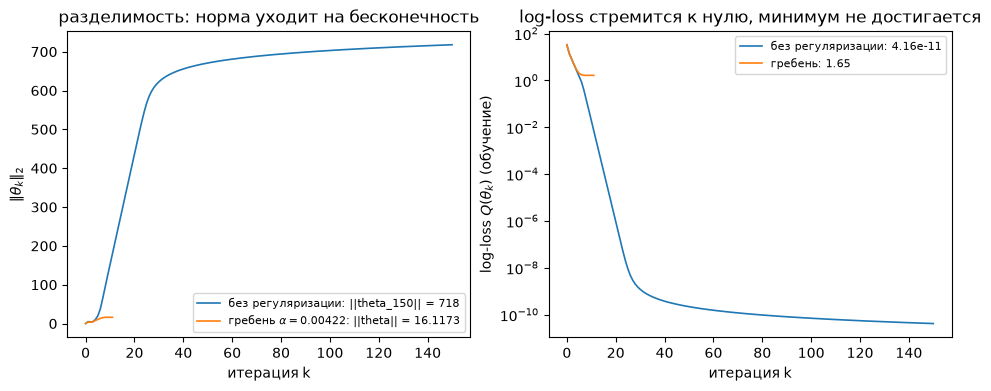

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), layout="constrained")

ax = axes[0]
ax.plot(np.arange(len(norm_plain_hist)), norm_plain_hist, "-", lw=1.2,
        label=f"без регуляризации: ||theta_150|| = {NORM_PLAIN:.3g}")
ax.plot(np.arange(len(norm_ridge_hist)), norm_ridge_hist, "-", lw=1.2,
        label=f"гребень $\\alpha = {ALPHA_RIDGE:.3g}$: ||theta|| = {NORM_RIDGE:.4f}")
ax.set_xlabel("итерация k")
ax.set_ylabel("$\\|\\theta_k\\|_2$")
ax.set_title("разделимость: норма уходит на бесконечность")
ax.legend(fontsize=8)

ax = axes[1]
ax.semilogy(np.arange(len(loss_plain)), loss_plain, "-", lw=1.2,
            label=f"без регуляризации: {loss_plain[-1]:.3g}")
ax.semilogy(np.arange(len(loss_ridge)), loss_ridge, "-", lw=1.2,
            label=f"гребень: {loss_ridge[-1]:.3g}")
ax.set_xlabel("итерация k")
ax.set_ylabel("log-loss $Q(\\theta_k)$ (обучение)")
ax.set_title("log-loss стремится к нулю, минимум не достигается")
ax.legend(fontsize=8)
fig.savefig(f"{FIGDIR}/fig-04.pdf", **SAVE_KW)

**Вывод:** механизм rem:separation подтвердился, количественный прогноз
— нет. Пункт «на последней итерации $\|\theta\|$ — порядка $10^3$ и
выше» **не подтвердился**: фактически $\|\theta_{150}\| = 717{,}8$ —
порог «$> 100$» пройден с запасом, но это ослабленная проверка. Темп
роста ниже прогноза, потому что градиент в машинной арифметике
обнуляется раньше, чем норма набирает $10^3$ (порог $\|\nabla Q\| <
10^{-8}$ пройден уже на итерации $24$, см. ниже): после сатурации
вероятностей до точных $0$ и $1$ IRLS оценку дальше не двигает, и норма
застывает на $7{,}2\cdot10^2$. Содержательный итог прежний: оценка
уходит на бесконечность, log-loss $4{,}2\cdot10^{-11}$, минимум не
достигается. Пункт «IRLS не останавливается по критерию градиента» **не
подтвердился, и это содержательно**: порог формально пройден уже на
итерации $24$. Градиент вдоль разделяющего луча убывает экспоненциально
вместе с log-loss, а в машинной арифметике вероятности сатурируют до
точных $0$ и $1$ — после чего $\nabla Q$ обнуляется в точности. Так что
критерий остановки по градиенту на разделимых данных *ненадёжен*: в точной
арифметике градиент стремится к нулю вдоль луча $t\varphi$ при $t \to
\infty$ и конечный порог достигается тоже. Верный стоп-сигнал здесь —
рост $\|\theta_k\|$ и стремление log-loss к нулю (что и предлагает
rem:separation: «остановка по изменению прогнозов»); утверждение theory.md
«оценка не существует» не опровергается — оценивать попросту нечего.
Регуляризация исправляет постановку: $\alpha = 0{,}0042$ по CV даёт
конечную $\|\theta\| = 16{,}1$; log-loss на отложенной выборке выше, чем
у разделимого решения ($0{,}386$ против $2{,}2\cdot10^{-4}$), как и
предсказано, — цена за устойчивость. Контроль score-уравнений: без
регуляризации $\sum\hat p - \sum y = -0{,}000000$ (свойство выполняется
предельно, $\hat p$ сатурировали к $y$); с гребнем отклонение $-0{,}042$
— оценочные уравнения точны только для нерегуляризованной задачи.

## Сводка: какие числа куда идут

In [10]:
rows = [
    ("kappa_2(A), пример 1", f"{KAPPA2_A:.6g}", "theory.md, раздел «Численная сторона МНК»"),
    ("d_n, пример 1", f"{d[-1]:.6g}", "theory.md, мотивация гребня"),
    ("alpha (1SE), пример 1", f"{ALPHA_1SE:.6g}", "theory.md, rem:ridge; слайды"),
    ("MSE(theta): ridge/OLS, пример 1", f"{RATIO_RIDGE:.6g}", "theory.md, смещение-дисперсия гребня"),
    ("MSE предсказания ridge/OLS на тесте, пример 1", f"{RATIO_TEST:.6g}",
     "theory.md, rem:ridge (alpha по CV)"),
    ("MSE(4 строк)/MSE(OLS), пример 1", f"{RATIO_ROW4:.6g}", "theory.md, теорема Гаусса — Маркова"),
    ("среднее RSS/(m-n), пример 1", f"{SIG_HAT2_MEAN:.6g}", "theory.md, теорема о несмещённой оценке sigma^2"),
    ("наклон NE, пример 2", f"{SLOPE_NE:.6g}", "theory.md, thm:normal-bad; слайды"),
    ("наклон QR, пример 2", f"{SLOPE_QR:.6g}", "theory.md, thm:qr; слайды"),
    ("kappa_2 диапазон, пример 2", f"{kappas.min():.3g} ... {kappas.max():.3g}", "theory.md, rem:perturb"),
    ("итераций IRLS, пример 3", f"{it_irls}", "theory.md, rem:irls-conv"),
    ("log-loss IRLS, пример 3", f"{IRLS_LOGLOSS:.6g}", "theory.md, раздел про IRLS"),
    ("итераций GD (eta = 1/L), пример 3", f"{it_gd}", "theory.md, раздел «Обучение первыми методами»"),
    ("eta0 SGD, пример 3", f"{ETA0_SGD}", "theory.md, SGD (выбор шага)"),
    ("accuracy / precision / recall, пример 3",
     f"{acc:.3f} / {prec:.3f} / {rec:.3f}", "theory.md, таблица метрик"),
    ("||theta_150|| без регуляризации, пример 4", f"{NORM_PLAIN:.6g}",
     "theory.md, rem:separation; слайды"),
    ("alpha (CV), пример 4", f"{ALPHA_RIDGE:.6g}", "theory.md, rem:separation"),
    ("||theta|| с гребнем, пример 4", f"{NORM_RIDGE:.6g}", "theory.md, rem:separation"),
]
print(f"{'величина':<42} {'значение':<28} куда идёт")
for name, val, dst in rows:
    print(f"{name:<42} {val:<28} {dst}")
print()
print("фигуры: fig-01.pdf (разброс коэффициентов, фильтр гребня), "
      "fig-02.pdf (kappa^2 против kappa), fig-03.pdf (данные, сходимость), "
      "fig-04.pdf (разделимость) — в questions/18-linear-logistic-regression/figures/")
print("README вопроса получает итог петли review-fix-loop, "
      "а не числа из этого ноутбука.")

величина                                   значение                     куда идёт
kappa_2(A), пример 1                       41.9428                      theory.md, раздел «Численная сторона МНК»
d_n, пример 1                              0.259158                     theory.md, мотивация гребня
alpha (1SE), пример 1                      3.98107                      theory.md, rem:ridge; слайды
MSE(theta): ridge/OLS, пример 1            0.687261                     theory.md, смещение-дисперсия гребня
MSE предсказания ridge/OLS на тесте, пример 1 1.08813                      theory.md, rem:ridge (alpha по CV)
MSE(4 строк)/MSE(OLS), пример 1            29.9424                      theory.md, теорема Гаусса — Маркова
среднее RSS/(m-n), пример 1                0.247271                     theory.md, теорема о несмещённой оценке sigma^2
наклон NE, пример 2                        2.02146                      theory.md, thm:normal-bad; слайды
наклон QR, пример 2                        1.02914